# Modelagem, Avaliação e Resultados

**Projeto:** Detecção de Fraude em Transações de Cartão de Crédito
**Disciplina:** Inteligência Artificial – 7ºJ SI - Noite | **Professor:** Prof. Dr. Leandro Zerbinatti
**Curso:** Sistemas de Informação – Faculdade de Computação e Informática – Universidade Presbiteriana Mackenzie

**Integrantes do grupo:**

| Nome | RA | E-mail |
|---|---|---|
| Anna Julia Santos de Paula | 10420681 | 10420681@mackenzista.com.br |
| Eduarda Dantas Azevedo Silva | 10419951 | 10419951@mackenzista.com.br |
| Sara de Oliveira Silva Omena | 10425441 | 10425441@mackenzista.com.br |

**Síntese do conteúdo deste arquivo:** Treinamento e comparação de modelos de classificação (Regressão Logística, Random Forest e XGBoost) com duas estratégias de desbalanceamento (SMOTE × `class_weight`), ajuste de hiperparâmetros, escolha do limiar de decisão, avaliação final no conjunto de teste (precisão, recall, F1, AUPRC), interpretação das variáveis e validação cruzada de estabilidade.

**Histórico de alterações:**

| Data | Autor | Descrição |
|---|---|---|
| 17/11/2026 | Eduarda Dantas Azevedo Silva | Criação do notebook de modelagem (N2): pipelines, comparação de modelos, tuning, limiar, avaliação no teste e importância das variáveis |


## 0. Visão geral

Fluxo do notebook:

1. Carregar os dados e remover duplicatas (mesmo tratamento de `preparacao_dados.ipynb`).
2. Dividir em **treino (60%)**, **validação (20%)** e **teste (20%)**, de forma estratificada. O teste é o mesmo 20% de `preparacao_dados.ipynb` (`random_state=42`) e só é usado no final.
3. Criar um *baseline* ingênuo, para mostrar por que a acurácia engana.
4. Comparar 3 algoritmos × 2 estratégias de desbalanceamento na validação, usando **AUPRC** (área sob a curva Precisão–Recall) como métrica principal.
5. Ajustar os hiperparâmetros do melhor modelo (`RandomizedSearchCV`).
6. Escolher o **limiar de decisão** na validação.
7. Avaliar uma única vez no teste.
8. Interpretar o modelo (importância das variáveis) e verificar a estabilidade com validação cruzada.

> Normalização e SMOTE ficam **dentro de um `Pipeline`** (`imblearn`). Assim eles são ajustados só nos dados de treino de cada etapa, sem vazamento de informação para validação ou teste.

## 1. Imports e configurações

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
SEED = 42
RESULTADOS = "../resultados"
os.makedirs(RESULTADOS, exist_ok=True)

## 2. Carregamento e limpeza

Removemos as linhas duplicadas antes de qualquer divisão, para que uma mesma transação não apareça ao mesmo tempo no treino e no teste.

In [3]:
df = pd.read_csv("../dataset/creditcard.csv")
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Linhas originais: {antes} | duplicatas removidas: {antes - len(df)} | restantes: {len(df)}")
print(f"Fraudes: {df['Class'].sum()} ({df['Class'].mean()*100:.3f}%)")

X = df.drop(columns="Class")
y = df["Class"]

Linhas originais: 284807 | duplicatas removidas: 1081 | restantes: 283726
Fraudes: 473 (0.167%)


## 3. Divisão treino / validação / teste (60/20/20, estratificada)

In [4]:
# 1º split: separa o teste (20%) — mesmo corte de preparacao_dados.ipynb
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
# 2º split: do restante, 25% vira validação (= 20% do total)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)

for nome, yy in [("Treino", y_train), ("Validação", y_val), ("Teste", y_test)]:
    print(f"{nome:10s}: {len(yy):6d} linhas | fraudes: {yy.sum():3d} ({yy.mean()*100:.3f}%)")

Treino    : 170235 linhas | fraudes: 284 (0.167%)
Validação :  56745 linhas | fraudes:  94 (0.166%)
Teste     :  56746 linhas | fraudes:  95 (0.167%)


## 4. Funções auxiliares

- `preprocessador()`: normaliza só `Amount` e `Time` (V1–V28 já vêm do PCA).
- `avaliar()`: calcula as métricas a partir das probabilidades previstas e de um limiar.

In [5]:
def preprocessador():
    return ColumnTransformer([("escala", StandardScaler(), ["Amount", "Time"])], remainder="passthrough")

def avaliar(y_true, proba, limiar=0.5):
    pred = (proba >= limiar).astype(int)
    return {
        "Acurácia": accuracy_score(y_true, pred),
        "Precisão": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "AUPRC": average_precision_score(y_true, proba),
        "ROC-AUC": roc_auc_score(y_true, proba),
    }

# razão normal/fraude no treino — usada como peso da classe fraude no XGBoost
peso_fraude = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Peso da classe fraude (scale_pos_weight): {peso_fraude:.1f}")

Peso da classe fraude (scale_pos_weight): 598.4


## 5. Baseline: por que a acurácia engana

Um "modelo" que sempre responde **legítima** acerta quase 100% das transações, mas não detecta nenhuma fraude.

In [6]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pd.DataFrame([avaliar(y_val, baseline.predict_proba(X_val)[:, 1])], index=["Baseline (sempre legítima)"]).round(4)

,Acurácia,Precisão,Recall,F1,AUPRC,ROC-AUC
Baseline (sempre legítima),0.9983,0.0,0.0,0.0,0.0017,0.5


## 6. Comparação de modelos × estratégias de desbalanceamento

| Estratégia | Como funciona |
|---|---|
| `class_weight` | Mantém os dados originais e dá **peso maior** aos erros na classe fraude durante o treino |
| SMOTE | Gera **fraudes sintéticas** no treino (interpolando vizinhos próximos) até equilibrar as classes |

Algoritmos:
- **Regressão Logística**: modelo linear e interpretável (referência).
- **Random Forest**: *ensemble* de árvores de decisão treinadas em paralelo (*bagging*).
- **XGBoost**: *ensemble* de árvores treinadas em sequência, cada uma corrigindo os erros da anterior (*boosting*).

Todos são treinados no **treino** e comparados na **validação**.

> ⏱️ Esta célula é a mais demorada (Random Forest + SMOTE): de 5 a 10 minutos, dependendo do computador.

In [7]:
def montar(modelo, usar_smote):
    etapas = [("prep", preprocessador())]
    if usar_smote:
        etapas.append(("smote", SMOTE(random_state=SEED)))
    etapas.append(("modelo", modelo))
    return Pipeline(etapas)

candidatos = {
    "Reg. Logística | class_weight": montar(LogisticRegression(max_iter=2000, class_weight="balanced"), False),
    "Reg. Logística | SMOTE":        montar(LogisticRegression(max_iter=2000), True),
    "Random Forest | class_weight":  montar(RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED), False),
    "Random Forest | SMOTE":         montar(RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED), True),
    "XGBoost | class_weight":        montar(XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, scale_pos_weight=peso_fraude, eval_metric="aucpr", n_jobs=-1, random_state=SEED), False),
    "XGBoost | SMOTE":               montar(XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, eval_metric="aucpr", n_jobs=-1, random_state=SEED), True),
}

resultados_val, probas_val = {}, {}
for nome, pipe in candidatos.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    probas_val[nome] = pipe.predict_proba(X_val)[:, 1]
    resultados_val[nome] = {**avaliar(y_val, probas_val[nome]), "Tempo treino (s)": time.time() - t0}
    print(f"{nome:32s} AUPRC={resultados_val[nome]['AUPRC']:.4f}  ({resultados_val[nome]['Tempo treino (s)']:.0f}s)")

tabela_val = pd.DataFrame(resultados_val).T.sort_values("AUPRC", ascending=False)
tabela_val.round(4).to_csv(f"{RESULTADOS}/comparacao_validacao.csv")
tabela_val.round(4)

Reg. Logística | class_weight    AUPRC=0.7868  (1s)
Reg. Logística | SMOTE           AUPRC=0.7886  (1s)
Random Forest | class_weight     AUPRC=0.8727  (8s)
Random Forest | SMOTE            AUPRC=0.8750  (32s)
XGBoost | class_weight           AUPRC=0.8812  (3s)
XGBoost | SMOTE                  AUPRC=0.8690  (4s)


,Acurácia,Precisão,Recall,F1,AUPRC,ROC-AUC,Tempo treino (s)
XGBoost | class_weight,0.9996,0.9101,0.8617,0.8852,0.8812,0.9804,2.6471
Random Forest | SMOTE,0.9996,0.9205,0.8617,0.8901,0.8750,0.9620,32.2831
Random Forest | class_weight,0.9996,0.9610,0.7872,0.8655,0.8727,0.9457,8.1621
XGBoost | SMOTE,0.9988,0.5942,0.8723,0.7069,0.8690,0.9730,4.2491
Reg. Logística | SMOTE,0.9714,0.0500,0.9043,0.0948,0.7886,0.9780,0.9105
Reg. Logística | class_weight,0.9735,0.0538,0.9043,0.1016,0.7868,0.9788,0.5430


### Curvas Precisão–Recall na validação

Quanto mais a curva se aproxima do canto superior direito, melhor. A AUPRC é a área sob essa curva.

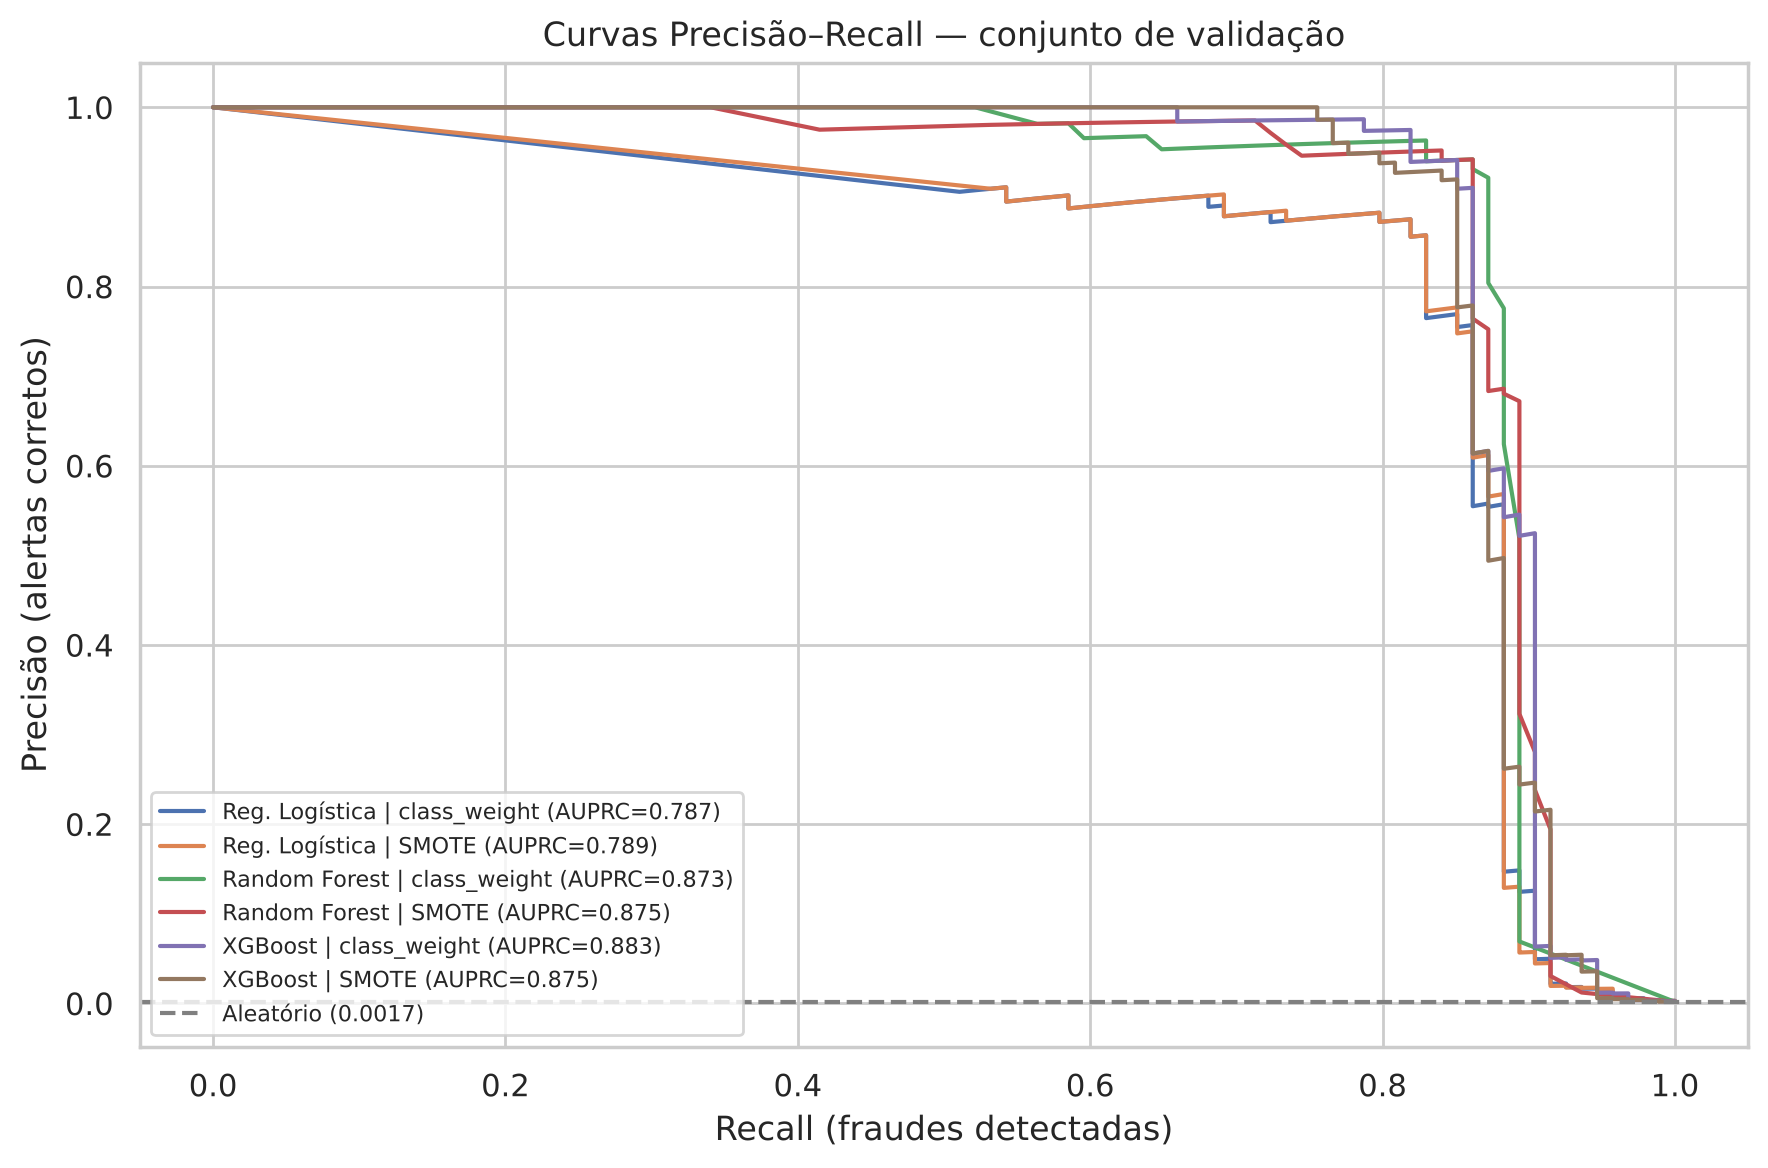

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
for nome, proba in probas_val.items():
    p, r, _ = precision_recall_curve(y_val, proba)
    ax.plot(r, p, label=f"{nome} (AUPRC={average_precision_score(y_val, proba):.3f})")
ax.axhline(y_val.mean(), ls="--", c="gray", label=f"Aleatório ({y_val.mean():.4f})")
ax.set_xlabel("Recall (fraudes detectadas)"); ax.set_ylabel("Precisão (alertas corretos)")
ax.set_title("Curvas Precisão–Recall — conjunto de validação"); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(f"{RESULTADOS}/curvas_pr_validacao.png", dpi=150); plt.show()

## 7. Ajuste de hiperparâmetros do XGBoost

`RandomizedSearchCV` testa 15 combinações aleatórias de hiperparâmetros com validação cruzada estratificada de 3 *folds* **no treino**, otimizando a AUPRC (`average_precision`).

In [8]:
busca = RandomizedSearchCV(
    montar(XGBClassifier(scale_pos_weight=peso_fraude, eval_metric="aucpr", n_jobs=-1, random_state=SEED), False),
    param_distributions={
        "modelo__n_estimators": [200, 300, 500, 700],
        "modelo__learning_rate": [0.02, 0.05, 0.1],
        "modelo__max_depth": [3, 4, 6, 8],
        "modelo__subsample": [0.7, 0.85, 1.0],
        "modelo__colsample_bytree": [0.6, 0.8, 1.0],
        "modelo__min_child_weight": [1, 3, 5],
    },
    n_iter=15, scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=1, verbose=0,
)
t0 = time.time()
busca.fit(X_train, y_train)
print(f"Tempo: {time.time()-t0:.0f}s")
print("Melhores hiperparâmetros:", {k.replace('modelo__', ''): v for k, v in busca.best_params_.items()})
print(f"AUPRC média na validação cruzada: {busca.best_score_:.4f}")

modelo_final = busca.best_estimator_
proba_val_final = modelo_final.predict_proba(X_val)[:, 1]
print(f"AUPRC na validação (XGBoost ajustado): {average_precision_score(y_val, proba_val_final):.4f}")

Tempo: 112s
Melhores hiperparâmetros: {'subsample': 0.85, 'n_estimators': 700, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
AUPRC média na validação cruzada: 0.8358
AUPRC na validação (XGBoost ajustado): 0.8822


## 8. Escolha do limiar de decisão

O limiar padrão (0,5) nem sempre é o melhor em dados desbalanceados. Para escolhê-lo sem olhar o teste:

1. Geramos probabilidades **fora da amostra** (*out-of-fold*) com validação cruzada de 5 *folds* em treino + validação. Isso dá 378 fraudes para basear a escolha, contra só 94 da validação sozinha.
2. Escolhemos o limiar que **maximiza o F2**, uma média entre precisão e recall que dá **peso maior ao recall**. Deixar uma fraude passar (falso negativo) costuma custar mais do que um alerta a mais, mas o F2 ainda penaliza o excesso de falsos positivos (clientes bloqueados sem motivo).

Limiar escolhido (máx. F2, out-of-fold): 0.732


,Limiar,Precisão,Recall,F1
0,0.1000,0.8175,0.8413,0.8292
1,0.3000,0.8824,0.8333,0.8571
2,0.5000,0.9023,0.8307,0.8650
3,0.7000,0.9206,0.8280,0.8719
4,0.9000,0.9417,0.8122,0.8722
5,0.7321,0.9288,0.8280,0.8755


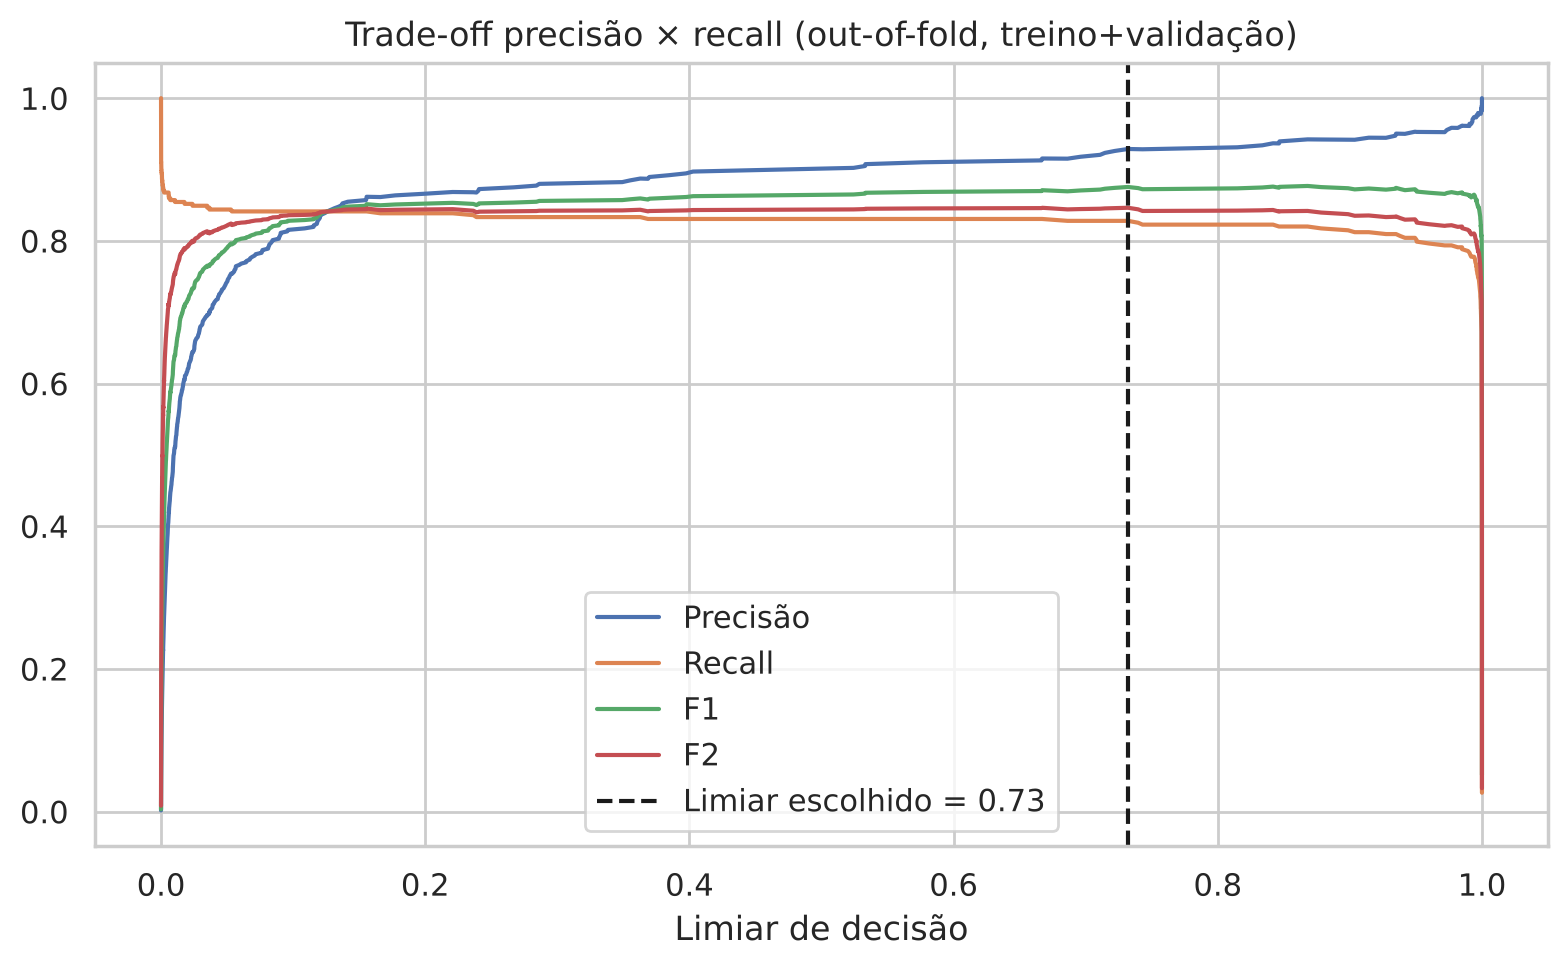

In [9]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

X_tv, y_tv = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
proba_oof = cross_val_predict(clone(modelo_final), X_tv, y_tv,
                              cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
                              method="predict_proba")[:, 1]

p, r, lim = precision_recall_curve(y_tv, proba_oof)
f2s = 5 * p[:-1] * r[:-1] / (4 * p[:-1] + r[:-1] + 1e-12)
f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
LIMIAR = float(lim[np.argmax(f2s)])
print(f"Limiar escolhido (máx. F2, out-of-fold): {LIMIAR:.3f}")

tabela_limiar = pd.DataFrame([{"Limiar": t, **avaliar(y_tv, proba_oof, t)} for t in [0.1, 0.3, 0.5, 0.7, 0.9, LIMIAR]])
display(tabela_limiar[["Limiar", "Precisão", "Recall", "F1"]].round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(lim, p[:-1], label="Precisão"); ax.plot(lim, r[:-1], label="Recall")
ax.plot(lim, f1s, label="F1"); ax.plot(lim, f2s, label="F2")
ax.axvline(LIMIAR, ls="--", c="k", label=f"Limiar escolhido = {LIMIAR:.2f}")
ax.set_xlabel("Limiar de decisão"); ax.set_title("Trade-off precisão × recall (out-of-fold, treino+validação)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{RESULTADOS}/tradeoff_limiar.png", dpi=150); plt.show()

## 9. Avaliação final no conjunto de teste

O teste é usado **uma única vez**, aqui. Comparamos todos os modelos (limiar 0,5) com o modelo final (XGBoost ajustado + limiar escolhido).

In [10]:
linhas = {"Baseline (sempre legítima)": avaliar(y_test, baseline.predict_proba(X_test)[:, 1])}
for nome, pipe in candidatos.items():
    linhas[nome] = avaliar(y_test, pipe.predict_proba(X_test)[:, 1])
proba_test_final = modelo_final.predict_proba(X_test)[:, 1]
linhas["XGBoost ajustado (limiar 0,5)"] = avaliar(y_test, proba_test_final)
linhas[f"XGBoost ajustado (limiar {LIMIAR:.2f}) ★ FINAL"] = avaliar(y_test, proba_test_final, LIMIAR)

tabela_teste = pd.DataFrame(linhas).T
tabela_teste.round(4).to_csv(f"{RESULTADOS}/metricas_teste.csv")
tabela_teste.round(4)

,Acurácia,Precisão,Recall,F1,AUPRC,ROC-AUC
Baseline (sempre legítima),0.9983,0.0000,0.0000,0.0000,0.0017,0.5000
Reg. Logística | class_weight,0.9724,0.0507,0.8737,0.0958,0.6918,0.9645
Reg. Logística | SMOTE,0.9703,0.0473,0.8737,0.0897,0.6903,0.9593
Random Forest | class_weight,0.9995,0.9710,0.7053,0.8171,0.8136,0.9298
Random Forest | SMOTE,0.9995,0.9125,0.7684,0.8343,0.8103,0.9441
XGBoost | class_weight,0.9995,0.9125,0.7684,0.8343,0.8096,0.9700
XGBoost | SMOTE,0.9987,0.5878,0.8105,0.6814,0.8075,0.9730
"XGBoost ajustado (limiar 0,5)",0.9995,0.9367,0.7789,0.8506,0.8338,0.9717
XGBoost ajustado (limiar 0.73) ★ FINAL,0.9996,0.9730,0.7579,0.8521,0.8338,0.9717


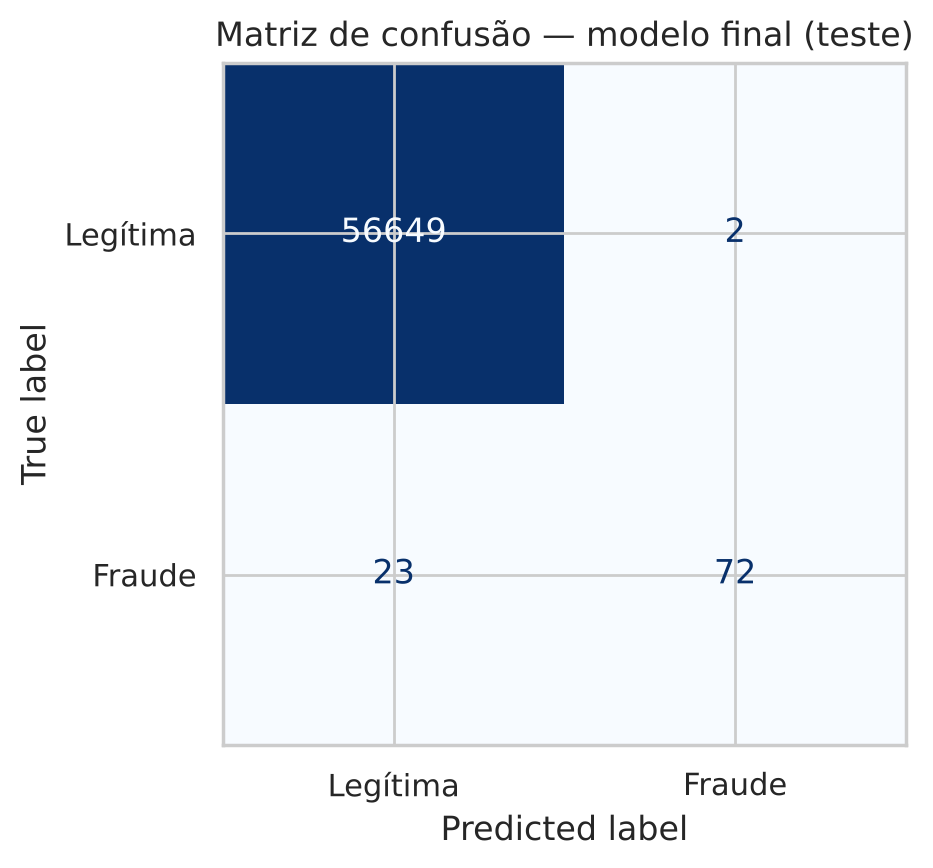

              precision    recall  f1-score   support

    Legítima     0.9996    1.0000    0.9998     56651
      Fraude     0.9730    0.7579    0.8521        95

    accuracy                         0.9996     56746
   macro avg     0.9863    0.8789    0.9259     56746
weighted avg     0.9995    0.9996    0.9995     56746

Fraudes no teste: 95 | detectadas: 72 | não detectadas (FN): 23
Transações legítimas bloqueadas por engano (FP): 2 de 56651 (0.004%)


In [11]:
pred_final = (proba_test_final >= LIMIAR).astype(int)
cm = confusion_matrix(y_test, pred_final)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Legítima", "Fraude"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Matriz de confusão — modelo final (teste)")
plt.tight_layout(); plt.savefig(f"{RESULTADOS}/matriz_confusao_teste.png", dpi=150); plt.show()

print(classification_report(y_test, pred_final, target_names=["Legítima", "Fraude"], digits=4))
print(f"Fraudes no teste: {tp + fn} | detectadas: {tp} | não detectadas (FN): {fn}")
print(f"Transações legítimas bloqueadas por engano (FP): {fp} de {tn + fp} ({fp/(tn+fp)*100:.3f}%)")

## 10. Interpretação: quais variáveis mais pesam na decisão?

Importância por *gain* do XGBoost: quanto cada variável contribui, em média, para melhorar as divisões das árvores. Isso ajuda a reduzir o efeito "caixa-preta" discutido na seção de ética.

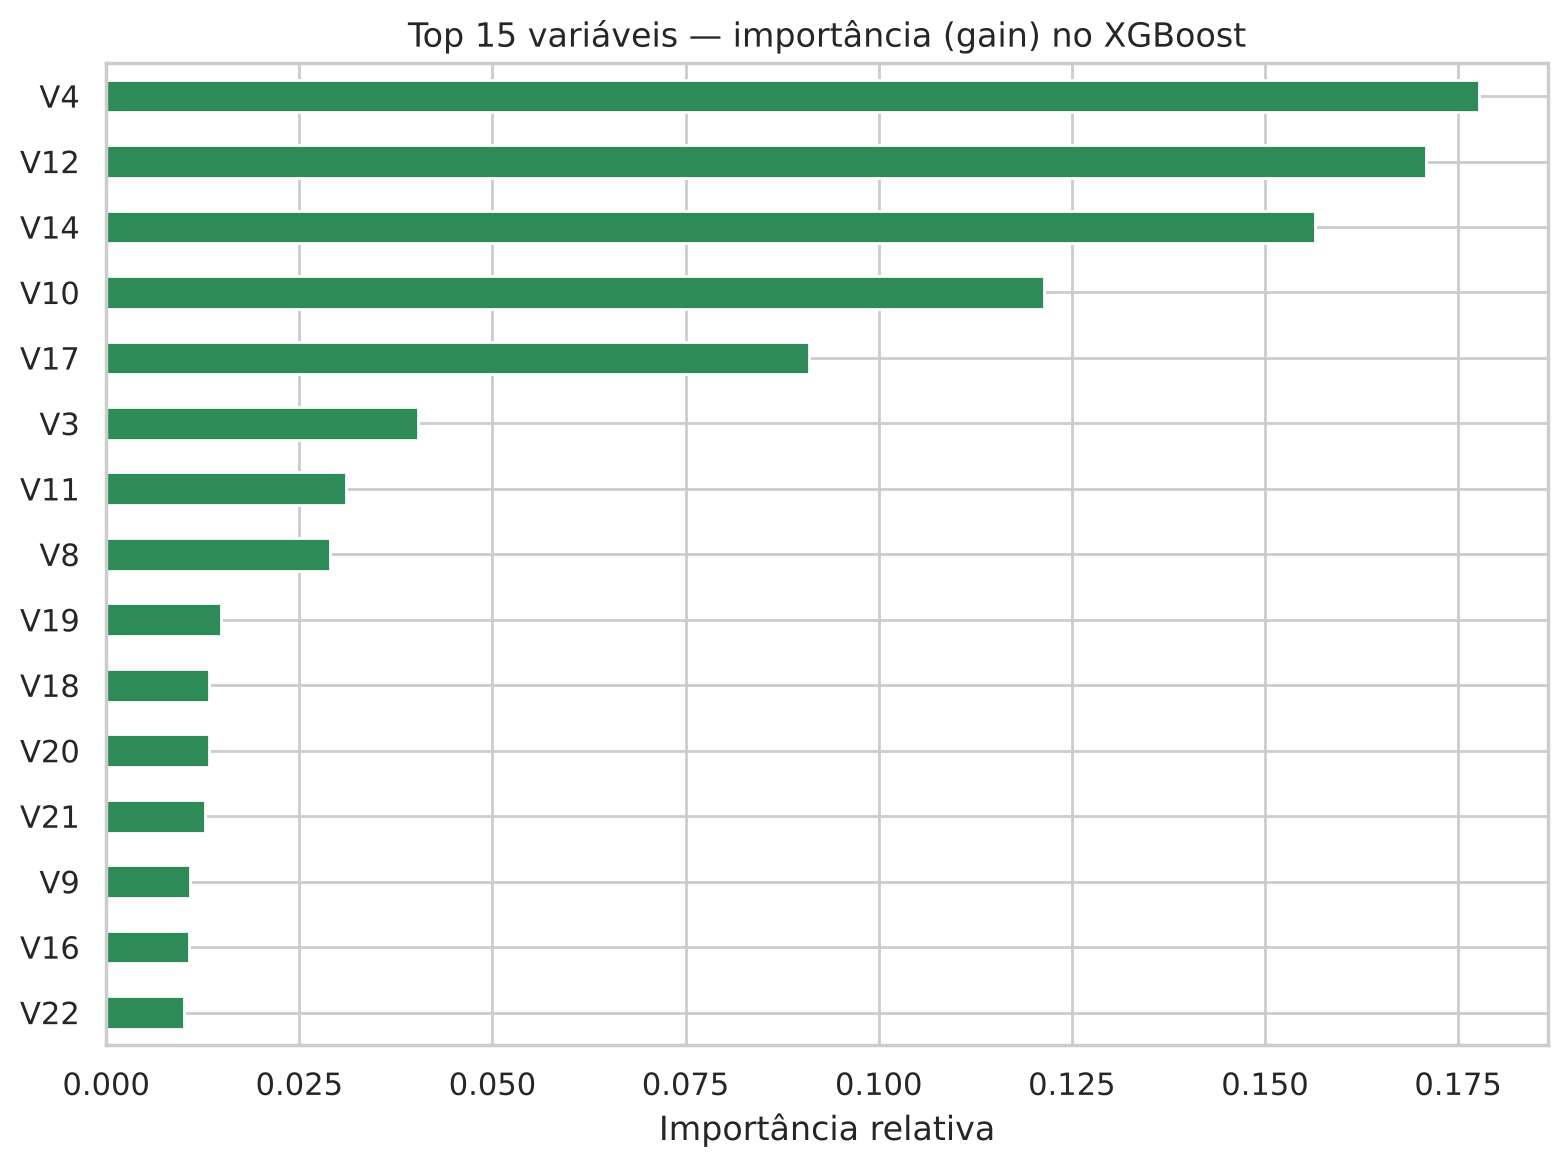

V4     0.1778
V12    0.1709
V14    0.1565
V10    0.1214
V17    0.0910
V3     0.0404
V11    0.0311
V8     0.0290
V19    0.0148
V18    0.0133
dtype: float64

In [12]:
xgb = modelo_final.named_steps["modelo"]
nomes = ["Amount", "Time"] + [c for c in X.columns if c not in ("Amount", "Time")]  # ordem de saída do ColumnTransformer
gain = xgb.get_booster().get_score(importance_type="gain")
imp = pd.Series({nomes[int(k[1:])]: v for k, v in gain.items()}).sort_values(ascending=False)
imp = imp / imp.sum()
imp.round(4).to_csv(f"{RESULTADOS}/importancia_variaveis.csv")

fig, ax = plt.subplots(figsize=(8, 6))
imp.head(15)[::-1].plot(kind="barh", ax=ax, color="seagreen")
ax.set_title("Top 15 variáveis — importância (gain) no XGBoost"); ax.set_xlabel("Importância relativa")
plt.tight_layout(); plt.savefig(f"{RESULTADOS}/importancia_variaveis.png", dpi=150); plt.show()
imp.head(10).round(4)

## 11. Estabilidade: validação cruzada estratificada (5 folds)

Reavaliamos a configuração final em 5 partições diferentes de treino+validação, para verificar se o desempenho não depende de um corte específico dos dados.

In [13]:
cv = cross_validate(modelo_final, X_tv, y_tv,
                    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
                    scoring={"AUPRC": "average_precision", "ROC-AUC": "roc_auc", "Recall": "recall", "Precisão": "precision"}, n_jobs=1)
estab = pd.DataFrame({m: [cv[f"test_{m}"].mean(), cv[f"test_{m}"].std()] for m in ["AUPRC", "ROC-AUC", "Recall", "Precisão"]}, index=["Média", "Desvio padrão"])
estab.round(4).to_csv(f"{RESULTADOS}/validacao_cruzada.csv")
estab.round(4)

,AUPRC,ROC-AUC,Recall,Precisão
Média,0.8518,0.9757,0.8306,0.9037
Desvio padrão,0.0288,0.0083,0.0411,0.0363


## 12. Salvar o modelo final

In [14]:
joblib.dump({"pipeline": modelo_final, "limiar": LIMIAR}, f"{RESULTADOS}/modelo_final.joblib")
print("Modelo salvo em", f"{RESULTADOS}/modelo_final.joblib")

# Exemplo de uso: classificar uma transação do teste
exemplo = X_test.iloc[[int(np.argmax(y_test.values))]]  # primeira fraude do teste
prob = modelo_final.predict_proba(exemplo)[0, 1]
print(f"Probabilidade de fraude: {prob:.4f} -> {'FRAUDE' if prob >= LIMIAR else 'legítima'}")

Modelo salvo em ../resultados/modelo_final.joblib
Probabilidade de fraude: 0.9974 -> FRAUDE


## 13. Conclusões

- **Acurácia engana:** o *baseline* que sempre responde "legítima" tem 99,83% de acurácia e não detecta nenhuma fraude. Por isso a comparação usou AUPRC, precisão, recall e F1.
- **Comparação de modelos:** os *ensembles* (Random Forest e XGBoost) superaram com folga a Regressão Logística. A Logística tem recall alto, mas precisão de ~5%: cerca de 19 alarmes falsos para cada fraude real. Isso confirma o resultado esperado na N1.
- **SMOTE × `class_weight`:** com XGBoost e Random Forest, as duas estratégias deram AUPRC parecida. O `class_weight` foi igual ou melhor, sem criar dados sintéticos e treinando bem mais rápido. Com XGBoost, o SMOTE derrubou a precisão (muitos falsos positivos).
- **Modelo final (XGBoost ajustado + `class_weight` + limiar escolhido por F2):** no teste, nunca visto antes, detectou **72 das 95 fraudes (recall ≈ 76%)** e bloqueou por engano **apenas 2 de 56.651 transações legítimas** (precisão ≈ 97%), com AUPRC ≈ 0,83.
- **Estabilidade:** na validação cruzada de 5 *folds*, a AUPRC média foi ≈ 0,85, com desvio padrão ≈ 0,03. O recall no teste (≈ 76%) ficou um pouco abaixo da média da validação cruzada (≈ 83%), uma variação esperada com só 95 fraudes no teste.
- **Interpretação:** as variáveis mais importantes foram V4, V12, V14, V10 e V17, as mesmas que mais se correlacionavam com `Class` na análise exploratória. `Amount` e `Time` tiveram pouco peso.
- **Limitações:** as variáveis são componentes de PCA anônimos (não dá para explicar a decisão em termos de negócio), os dados cobrem só 2 dias de 2013 e cerca de 1 em cada 4 fraudes ainda passa. Trabalhos futuros: features temporais e de comportamento do cliente, ajuste do limiar por custo financeiro real e explicações por transação (por exemplo, SHAP).